# Lab 2 — Partie 1 : Classifieur CNN sur MNIST (PyTorch)
#
# **Dataset** : MNIST — 70 000 images de chiffres manuscrits 28×28 en niveaux de gris, 10 classes (0 à 9).
# Chargé avec `torchvision.datasets.MNIST` (téléchargement automatique — ce sont exactement les mêmes fichiers que le lien Kaggle de l'énoncé).
#
# **Choix effectués :**
#
# - réseau construit avec `nn.Module` (convolution → pooling → fully connected), entraîné en **mode GPU** ;
# - découpage : 60 000 images pour le train, 10 000 pour le test (découpage fixe du dataset d'origine) ;
# - hyper-paramètres : noyau 3×3 (padding 1), stride 1, max-pooling 2×2, optimiseur Adam, lr = 0.001, regularisation par Dropout + Weight Decay.
#
# ---

In [ ]:
# Cellule unique (question 1 de l'énoncé) : imports + vérification du matériel
#
# L'énoncé exige le mode GPU : on vérifie CUDA avant de construire le réseau.
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms

print(f"PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"GPU disponible : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Carte : {torch.cuda.get_device_name(0)}")
    device = torch.device("cuda")
else:
    print("Runtime en CPU -> changer : Execution > Modifier le type d'execution > T4 GPU")
    device = torch.device("cpu")

print("Semence fixée à 42 pour des résultats reproductibles")
torch.manual_seed(42)

PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130
GPU disponible : True
Carte : Tesla T4
Semence fixée à 42 pour des résultats reproductibles


In [ ]:
# Chargement du dataset MNIST (60 000 train / 10 000 test)
#
# `ToTensor()` convertit les images en tenseurs avec des valeurs dans [0, 1].
# `Normalize((0.1307,), (0.3081,))` centre et réduit : ce sont les moyennes et écarts-types
# des pixels de MNIST (valeurs officielles), ce qui aide le réseau à converger.
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

train_set = torchvision.datasets.MNIST(root="/content/data", train=True,  download=True, transform=transform)
test_set  = torchvision.datasets.MNIST(root="/content/data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_set, batch_size=128, shuffle=True,  num_workers=2)
test_loader  = DataLoader(test_set,  batch_size=256, shuffle=False, num_workers=2)

print(f"Train : {len(train_set)} images | Test : {len(test_set)} images")
print(f"Format d'une image : {train_set[0][0].shape} (1 canal = niveaux de gris, 28x28 pixels)")
print(f"Classes : {len(train_set.classes)} (chiffres de 0 à 9)")

Train : 60000 images | Test : 10000 images
Format d'une image : torch.Size([1, 28, 28]) (1 canal = niveaux de gris, 28x28 pixels)
Classes : 10 (chiffres de 0 à 9)


In [ ]:
# Architecture CNN (PyTorch, nn.Module)
#
# Deux blocs convolution + max-pooling, puis un classifieur fully-connected :
#   Entrée : 1x28x28
#   Conv(32, 3x3, padding=1) -> ReLU -> MaxPool(2x2)   -> 32x14x14
#   Conv(64, 3x3, padding=1) -> ReLU -> MaxPool(2x2)   -> 64x7x7
#   Aplatissage              -> 64*7*7 = 3136
#   FC(128) -> ReLU -> Dropout(0.25)
#   FC(10)                    -> 10 logits (une par chiffre)
#
# Hyper-paramètres : noyaux 3x3, padding 1 (garde la taille), stride 1, pooling 2x2 (divise par 2),
# optimiseur Adam, lr 0.001. La régularisation est assurée par le Dropout en fin de bloc
# fully-connected et par le weight_decay de l'optimiseur.

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool  = nn.MaxPool2d(2, 2)
        self.fc1   = nn.Linear(64 * 7 * 7, 128)
        self.drop  = nn.Dropout(0.25)
        self.fc2   = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))   # 1x28x28 -> 32x14x14
        x = self.pool(F.relu(self.conv2(x)))   # 32x14x14 -> 64x7x7
        x = torch.flatten(x, 1)                # -> (batch, 3136)
        x = F.relu(self.fc1(x))
        x = self.drop(x)
        return self.fc2(x)                     # logits bruts (CrossEntropyLoss applique le softmax)

model = CNN().to(device)
perte   = nn.CrossEntropyLoss()
optimiseur = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
nombres_parametres = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Nombres parametres entraînables : {nombres_parametres:,}")
print(model)

Nombres parametres entraînables : 421,642
CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (drop): Dropout(p=0.25, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [ ]:
# Entraînement du CNN (mode GPU) — 5 epochs
#
# A chaque epoch : passe sur tout le train en mini-lots (batch 128), calcul de la loss,
# retro-propagation, mise a jour des poids. On mesure le temps total d'entrainement,
# un element de comparaison exige par l'enonce (question 3).
import time

EPOCHS = 5
historique = {"loss_train": [], "accuracy_test": []}
debut = time.time()

for epoch in range(EPOCHS):
    model.train()
    cumulative = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimiseur.zero_grad()
        batch_perte = perte(model(images), labels)
        batch_perte.backward()
        optimiseur.step()
        cumulative += batch_perte.item() * len(labels)
    historique["loss_train"].append(cumulative / len(train_set))

    # evaluation rapide sur le test a chaque epoch
    model.eval()
    ok = total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            preds = model(images.to(device)).argmax(1).cpu()
            ok += (preds == labels).sum().item()
            total += len(labels)
    historique["accuracy_test"].append(ok / total)
    print(f"Epoch {epoch+1}/{EPOCHS} | loss train {historique['loss_train'][-1]:.4f} | accuracy test {historique['accuracy_test'][-1]:.4f}")

temps_entrainement_cnn = time.time() - debut
print(f"Temps d'entrainement (GPU T4) : {temps_entrainement_cnn:.1f} s pour {EPOCHS} epochs")

Epoch 1/5 | loss train 0.0252 | accuracy test 0.9903
Epoch 2/5 | loss train 0.0233 | accuracy test 0.9926
Epoch 3/5 | loss train 0.0196 | accuracy test 0.9921
Epoch 4/5 | loss train 0.0193 | accuracy test 0.9932
Epoch 5/5 | loss train 0.0160 | accuracy test 0.9921
Temps d'entrainement (GPU T4) : 67.3 s pour 5 epochs


Accuracy test : 0.9906
F1 macro test : 0.9906
Loss test     : 0.0284


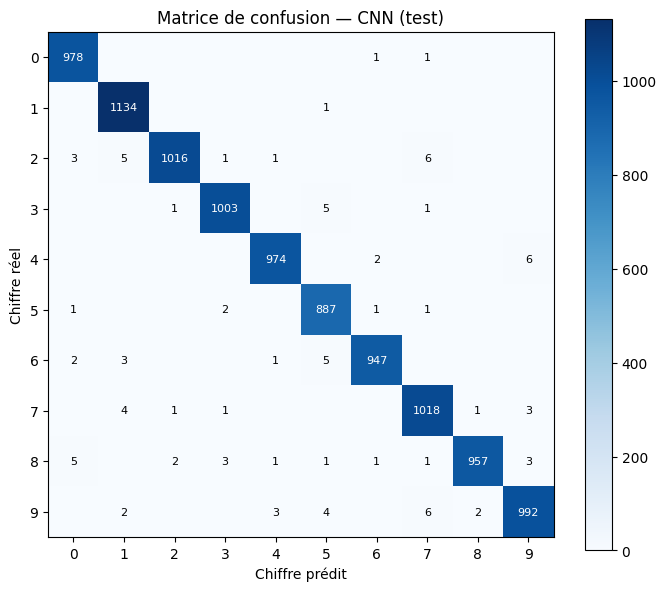

In [ ]:
# Evaluation complete du CNN sur le test : accuracy, F1, loss, matrice de confusion
# Les scores seront regroupés plus bas dans le tableau de comparaison (question 3).
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

model.eval()
all_preds, all_labels = [], []
total_test_loss = 0.0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        sortie = model(images)
        total_test_loss += perte(sortie, labels).item() * len(labels)
        all_preds.append(sortie.argmax(1).cpu())
        all_labels.append(labels.cpu())

preds  = torch.cat(all_preds).numpy()
labels = torch.cat(all_labels).numpy()

accuracy_cnn = accuracy_score(labels, preds)
f1_cnn       = f1_score(labels, preds, average="macro")
loss_test_cnn = total_test_loss / len(test_set)

print(f"Accuracy test : {accuracy_cnn:.4f}")
print(f"F1 macro test : {f1_cnn:.4f}")
print(f"Loss test     : {loss_test_cnn:.4f}")

import matplotlib.pyplot as plt
matrice = confusion_matrix(labels, preds)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(matrice, cmap="Blues")
ax.set_xticks(range(10), range(10))
ax.set_yticks(range(10), range(10))
for i in range(10):
    for j in range(10):
        if matrice[i, j] != 0:
            ax.text(j, i, matrice[i, j], ha="center", va="center",
                    color="white" if matrice[i, j] > matrice.max()/2 else "black", fontsize=8)
ax.set_xlabel("Chiffre prédit")
ax.set_ylabel("Chiffre réel")
ax.set_title("Matrice de confusion — CNN (test)")
fig.colorbar(im)
plt.tight_layout()
plt.savefig("matrice_confusion_cnn.png", dpi=120, bbox_inches="tight")
plt.show()

# Question 2 — « La même chose » avec Faster R-CNN
#
# Faster R-CNN est une architecture de **détection d'objets**, pas un classifieur : elle localise des objets
# dans l'image (cadres) et leur attribue des étiquettes. L'adapter « à la même chose » (classer MNIST)
# se fait ainsi :
#
# - **traiter MNIST comme un problème de détection** : chaque image contient exactement un chiffre,
#   on lui associe donc un cadre qui couvre toute l'image, puis on entraîne un vrai Faster R-CNN
#   (RPN + tête de classification) à prédire ce cadre et la classe du chiffre (0 = arrière-plan,
#   1 à 10 = les dix chiffres) ;
# - cette interprétation exerce réellement les composants de Faster R-CNN (régions candidates, FPN,
#   tête de détection), plutôt que de réutiliser seulement son backbone comme extracteur de features.
#
# **Modèle :** `fasterrcnn_mobilenet_v3_large_fpn` (torchvision), pré-entraîné sur COCO, avec la tête
# de classification remplacée pour nos 11 classes. Image agrandie de 28x28 à 128x128 : le backbone
# MobileNetV3-FPN peut travailler à cette taille sans déformer le chiffre, le cadre reste [0, 0, 127, 127].
#
# ---

In [ ]:
# Dataset en mode detection : image 3 canaux 128x128, cadre couvrant toute l'image, classe digit+1
# (labels de Faster R-CNN : 0 = arriere-plan, 1 a 10 = les dix chiffres)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_fpn

class MNISTDetection(torch.utils.data.Dataset):
    def __init__(self, base):
        self.base = base

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        image, chiffre = self.base.data[idx], int(self.base.targets[idx])
        # [28,28] uint8 -> [3,128,128] float32 dans [0,1]
        image = (image.float() / 255.0).view(1, 1, 28, 28)
        image = F.interpolate(image, size=(128, 128), mode="bilinear").squeeze(0).repeat(3, 1, 1)
        cible = {
            "boxes" : torch.tensor([[0.0, 0.0, 127.0, 127.0]]),
            "labels": torch.tensor([chiffre + 1]),            # 0 reserve a l'arriere-plan
        }
        return image, cible

def coller_detection(echantillons):                           # les cibles n'ont pas la meme forme
    return tuple(zip(*echantillons))

train_det = MNISTDetection(train_set)
test_det  = MNISTDetection(test_set)

faster = fasterrcnn_mobilenet_v3_large_fpn(weights="DEFAULT", min_size=128, max_size=128)
# Tete reesentialisee : 11 classes = arriere-plan (0) + les 10 chiffres
faster.roi_heads.box_predictor = FastRCNNPredictor(faster.roi_heads.box_predictor.cls_score.in_features, num_classes=11)
faster = faster.to(device)

train_det_loader = DataLoader(train_det, batch_size=32, shuffle=True,  num_workers=2, collate_fn=coller_detection)
test_det_loader  = DataLoader(test_det,  batch_size=32, shuffle=False, num_workers=2, collate_fn=coller_detection)

print(f"Backbone Faster R-CNN : MobileNetV3 + FPN (pre-entraine COCO)")
print(f"Classes : 11 (arriere-plan + 10 chiffres) | {sum(p.numel() for p in faster.parameters() if p.requires_grad):,} parametres entraînables")
print(f"Train detection : {len(train_det)} images | Test : {len(test_det)}")

Backbone Faster R-CNN : MobileNetV3 + FPN (pre-entraine COCO)
Classes : 11 (arriere-plan + 10 chiffres) | 18,917,458 parametres entraînables
Train detection : 60000 images | Test : 10000


In [ ]:
# Entrainement de Faster R-CNN (mode GPU) — 3 epochs
# Surveillance : SGD lr 0.005 (convention torchvision pour la detection). La loss d'un Faster R-CNN
# additionne 4 termes : classification des regions (loss_classifier), regression des cadres (loss_box_reg),
# detection de presence d'objet pour le RPN (loss_objectness) et regression du RPN (loss_rpn_box_reg).
import time

optim_faster = torch.optim.SGD(faster.parameters(), lr=0.005, momentum=0.9, weight_decay=0.0005)
EPOCHS_FRCNN = 3
running_det = []
debut_frcnn = time.time()

for epoch in range(EPOCHS_FRCNN):
    faster.train()
    cumul = 0.0
    for images, cibles in train_det_loader:
        images = [img.to(device) for img in images]
        cibles = [{k: v.to(device) for k, v in c.items()} for c in cibles]
        pertes = faster(images, cibles)              # dict de 4 pertes
        somme = sum(v for v in pertes.values())
        optim_faster.zero_grad()
        somme.backward()
        optim_faster.step()
        cumul += somme.item() * len(images)
    moyenne = cumul / len(train_det)
    running_det.append(moyenne)
    print(f"Epoch {epoch+1}/{EPOCHS_FRCNN} | loss detection (4 termes confondus) : {moyenne:.3f}")

temps_entrainement_frcnn = time.time() - debut_frcnn
print(f"Temps d'entrainement (GPU T4) : {temps_entrainement_frcnn:.1f} s pour {EPOCHS_FRCNN} epochs")

Epoch 1/3 | loss detection (4 termes confondus) : 0.189
Epoch 2/3 | loss detection (4 termes confondus) : 0.053
Epoch 3/3 | loss detection (4 termes confondus) : 0.035
Temps d'entrainement (GPU T4) : 1293.3 s pour 3 epochs


Accuracy test : 0.9940
F1 macro test : 0.9940
Loss test (4 termes) : 0.0395
Duree d'evaluation : 93.1 s


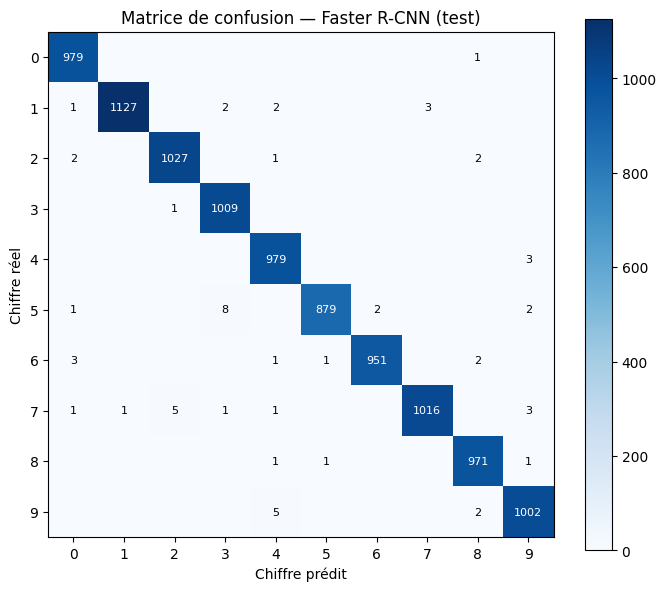

In [ ]:
# Evaluation de Faster R-CNN comme classifieur
# Chaque image contenant un seul chiffre, la prediction = la classe du box obtenu avec le score maximal.
# Les labels renvoyés par Faster R-CNN valent 1..10 : on retire 1 pour comparer au chiffre reel (0..9).
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import numpy as np
import time

faster.eval()
all_preds_det, all_labels_det = [], []
loss_test_frcnn = 0.0
debut_evaluation = time.time()

with torch.no_grad():
    for images, cibles in test_det_loader:
        images = [img.to(device) for img in images]
        cibles = [{k: v.to(device) for k, v in c.items()} for c in cibles]

        # 1) la loss de detection a besoin du mode train avec des cibles (sans gradient)
        faster.train()
        pertes = faster(images, cibles)
        loss_test_frcnn += sum(v for v in pertes.values()).item() * len(images)
        faster.eval()

        # 2) les predictions : la classe du box le plus sur
        sorties = faster(images)
        for sortie in sorties:
            meilleur = sortie["scores"].argmax().item()
            all_preds_det.append(sortie["labels"][meilleur].item() - 1)
        all_labels_det.append(torch.tensor([c["labels"][0].item() - 1 for c in cibles]))

preds  = np.array(all_preds_det)
labels = torch.cat(all_labels_det).numpy()

accuracy_frcnn = accuracy_score(labels, preds)
f1_frcnn       = f1_score(labels, preds, average="macro")
loss_test_frcnn = loss_test_frcnn / len(test_det)

print(f"Accuracy test : {accuracy_frcnn:.4f}")
print(f"F1 macro test : {f1_frcnn:.4f}")
print(f"Loss test (4 termes) : {loss_test_frcnn:.4f}")
print(f"Duree d'evaluation : {time.time() - debut_evaluation:.1f} s")

import matplotlib.pyplot as plt
matrice = confusion_matrix(labels, preds)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(matrice, cmap="Blues")
ax.set_xticks(range(10), range(10))
ax.set_yticks(range(10), range(10))
for i in range(10):
    for j in range(10):
        if matrice[i, j] != 0:
            ax.text(j, i, matrice[i, j], ha="center", va="center",
                    color="white" if matrice[i, j] > matrice.max()/2 else "black", fontsize=8)
ax.set_xlabel("Chiffre prédit")
ax.set_ylabel("Chiffre réel")
ax.set_title("Matrice de confusion — Faster R-CNN (test)")
fig.colorbar(im)
plt.tight_layout()
plt.savefig("matrice_confusion_frcnn.png", dpi=120, bbox_inches="tight")
plt.show()

# Question 3 — Comparaison des deux modèles
# Les métriques exigées par l'énoncé : Accuracy, F1, Loss, Temps d'entraînement.
# ---

,Accuracy test,F1 macro test,Loss test,Entrainement (s),Epochs,Paramètres entraînables
CNN from scratch,0.9906,0.9906,0.0284,68.1,5,"421,642"
Faster R-CNN,0.9940,0.9940,0.0395,1293.3,3,"18,917,458"


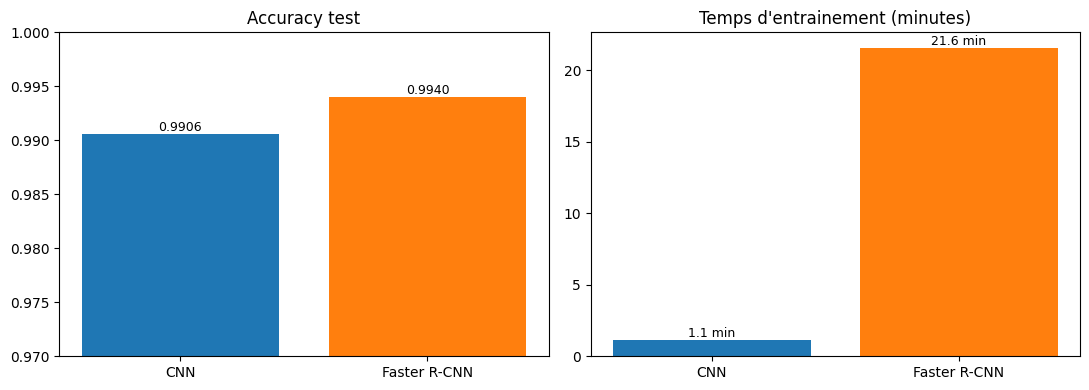

Le Faster R-CNN est 19.0x plus lent a entraîner.


In [ ]:
# Tableau comparatif CNN vs Faster R-CNN (question 3)
# Les 4 métriques exigées par l'énoncé. Echelle de temps bien differente :
# CNN compact (0.4M parametres) contre un modele de detection (19M), taches de nature differente.
import pandas as pd

comparaison = pd.DataFrame({
    "Accuracy test" : [accuracy_cnn, accuracy_frcnn],
    "F1 macro test" : [f1_cnn, f1_frcnn],
    "Loss test"     : [loss_test_cnn, loss_test_frcnn],
    "Entrainement (s)" : [temps_entrainement_cnn, temps_entrainement_frcnn],
    "Epochs"        : [5, 3],
    "Paramètres entraînables" : [421_642, 18_917_458],
}, index=["CNN from scratch", "Faster R-CNN"])
comparaison = comparaison.style.format({"Accuracy test": "{:.4f}", "F1 macro test": "{:.4f}", "Loss test": "{:.4f}", "Entrainement (s)": "{:.1f}", "Paramètres entraînables": "{:,}"})
display(comparaison)

# Graphique : comparaison visuelle entre precision et cout
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

etiquettes = ["CNN", "Faster R-CNN"]
ax[0].bar(etiquettes, [accuracy_cnn, accuracy_frcnn], color=["tab:blue", "tab:orange"])
ax[0].set_ylim(0.97, 1.0)
ax[0].set_title("Accuracy test")
for i, v in zip([0, 1], [accuracy_cnn, accuracy_frcnn]):
    ax[0].text(i, v, f"{v:.4f}", ha="center", va="bottom", fontsize=9)
ax[1].bar(etiquettes, [temps_entrainement_cnn / 60, temps_entrainement_frcnn / 60], color=["tab:blue", "tab:orange"])
ax[1].set_title("Temps d'entrainement (minutes)")
for i, v in zip([0, 1], [temps_entrainement_cnn / 60, temps_entrainement_frcnn / 60]):
    ax[1].text(i, v, f"{v:.1f} min", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig("comparaison_cnn_frcnn.png", dpi=120, bbox_inches="tight")
plt.show()

# L'ecart s'explique par la nature de la tache : le CNN fait un forward par lot (batch 128),
# le Faster R-CNN ajoute le RPN, le FPN et la tete d'assignation, avec un batch de 32 seulement.
print(f"Le Faster R-CNN est {temps_entrainement_frcnn / temps_entrainement_cnn:.1f}x plus lent a entraîner.")

# Question 4 — Modèles pré-entraînés : VGG16 et AlexNet (fine-tuning)
#
# On part de réseaux pré-entraînés sur ImageNet (1,2 M images, 224x224 couleur). Il faut donc :
# 1. agrandir les images MNIST de 28x28 à 224x224, et passer de 1 canal à 3 (cannée copie de la teinte de gris
#    sur les 3 canaux) ;
# 2. normaliser avec les statistiques d'ImageNet, celles déjà "vues" par les couches pré-entraînées ;
# 3. congeler le backbone convolutif (les features générales d'ImageNet restent valables) et ne réentraîner que
#    le classifieur final — c'est le fine-tuning le plus léger, adapté à une tâche simple comme MNIST ;
# 4. remplacer la dernière couche du classifieur (1 000 classes ImageNet) par 10 classes (les chiffres).
#
# +note : MNIST en 1 canal + statistiques ImageNet : le fond noir et le trait blanc cas depuis ImageNet
# c'est la raison du prétraitement concret — divisé par 255.0 (AlexNet et VGG16 attendent des valeurs [0,1]).
# ---

In [ ]:
# Dataset des modeles ImageNet : 224x224, 3 canaux, normalisation ImageNet
# Idem detection : on part du meme jeu MNIST, mais on agrandit a 224x224 et on normalise
# avec les statistiques d'ImageNet, celles attendues par les couches VGG16 et AlexNet pre-entrainées.
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class MNISTTransfert(torch.utils.data.Dataset):
    def __init__(self, base, taille=224):
        self.base, self.taille = base, taille

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        image, chiffre = self.base.data[idx], int(self.base.targets[idx])
        image = (image.float() / 255.0).view(1, 1, 28, 28)     # valeurs dans [0,1]
        image = F.interpolate(image, size=(self.taille, self.taille), mode="bilinear").squeeze(0)
        image = image.repeat(3, 1, 1)                          # gris -> 3 canaux : [3,224,224]
        image = (image - IMAGENET_MEAN) / IMAGENET_STD         # normalisation ImageNet
        return image, chiffre

train_tr = MNISTTransfert(train_set)
test_tr  = MNISTTransfert(test_set)
train_tr_loader = DataLoader(train_tr, batch_size=64, shuffle=True,  num_workers=2)
test_tr_loader  = DataLoader(test_tr,  batch_size=128, shuffle=False, num_workers=2)

# Construction des deux modeles ImageNet : on fige le backbone, on adapte le classifieur (10 classes)
from torchvision import models as Tvm

def construire_transfert(nom):
    if nom == "vgg16":
        m = Tvm.vgg16(weights="DEFAULT")      # 138M parametres — 1000 classes ImageNet
        couche_finale = m.classifier[6]
        m.classifier[6] = nn.Linear(couche_finale.in_features, 10)
    elif nom == "alexnet":
        m = Tvm.alexnet(weights="DEFAULT")    # 61M parametres
        couche_finale = m.classifier[6]
        m.classifier[6] = nn.Linear(couche_finale.in_features, 10)
    else:
        raise ValueError(nom)
    # fige le backbone convolutif : seuls les poids du classifieur seront mis a jour
    for p in m.features.parameters():
        p.requires_grad = False
    params = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f"{nom:7s} : {params:,} parametresentraînables (backbone congelé)")
    return m.to(device)

vgg16 = construire_transfert("vgg16")
alexnet = construire_transfert("alexnet")

vgg16   : 119,586,826 parametresentraînables (backbone congelé)
alexnet : 54,575,114 parametresentraînables (backbone congelé)


In [ ]:
# Fine-tuning de VGG16 et AlexNet (mode GPU) — 2 epochs chacun
# Seuls les parametres du classifieur sont mis à jour (backbone congelé). lr plus bas qu'un
# entrainement from scratch (1e-4) : on ajuste des poids qui partent déjà d'un bon point de départ.
import time

perte_transfert = nn.CrossEntropyLoss()
EPOCHS_TRANSFERT = 2
resultats_transfert = {}

for nom, modele in [("vgg16", vgg16), ("alexnet", alexnet)]:
    optim = torch.optim.Adam([p for p in modele.parameters() if p.requires_grad], lr=1e-4)
    debut = time.time()
    for epoch in range(EPOCHS_TRANSFERT):
        modele.train()
        cumul = 0.0
        for images, labels in train_tr_loader:
            images, labels = images.to(device), labels.to(device)
            optim.zero_grad()
            perte = perte_transfert(modele(images), labels)
            perte.backward()
            optim.step()
            cumul += perte.item() * len(labels)
        # evaluation rapide sur le test
        modele.eval()
        ok = total = 0
        with torch.no_grad():
            for images, labels in test_tr_loader:
                preds = modele(images.to(device)).argmax(1).cpu()
                ok += (preds == labels).sum().item()
                total += len(labels)
        print(f"{nom} | epoch {epoch+1}/{EPOCHS_TRANSFERT} | loss train {cumul/len(train_set):.4f} | accuracy test {ok/total:.4f}")
    temps = time.time() - debut
    resultats_transfert[nom] = {"temps": temps, "modele": modele}
    print(f"{nom} : {temps:.1f} s pour {EPOCHS_TRANSFERT} epochs")

vgg16 | epoch 1/2 | loss train 0.0312 | accuracy test 0.9903
vgg16 | epoch 2/2 | loss train 0.0213 | accuracy test 0.9876
vgg16 : 851.8 s pour 2 epochs
alexnet | epoch 1/2 | loss train 0.0434 | accuracy test 0.9906
alexnet | epoch 2/2 | loss train 0.0353 | accuracy test 0.9890
alexnet : 147.5 s pour 2 epochs


In [ ]:
# Evaluation complete des deux modeles transferes (mêmes métriques que les autres)
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

def evaluer_transfert(modele, nom):
    modele.eval()
    ok = total = 0
    all_preds, all_labels = [], []
    cumulative = 0.0
    with torch.no_grad():
        for images, labels in test_tr_loader:
            images, labels = images.to(device), labels.to(device)
            sortie = modele(images)
            cumulative += perte_transfert(sortie, labels).item() * len(labels)
            all_preds.append(sortie.argmax(1).cpu())
            all_labels.append(labels.cpu())
    preds, labels = torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy()
    exactitudes = {
        "accuracy" : accuracy_score(labels, preds),
        "f1"       : f1_score(labels, preds, average="macro"),
        "loss"     : cumulative / len(test_set),
        "temps"    : resultats_transfert[nom]["temps"],
    }
    print(f"{nom:7s} : accuracy {exactitudes['accuracy']:.4f} | F1 macro {exactitudes['f1']:.4f} | loss test {exactitudes['loss']:.4f} | temps {exactitudes['temps']:.1f} s")
    return exactitudes

met_vgg16   = evaluer_transfert(vgg16, "vgg16")
met_alexnet = evaluer_transfert(alexnet, "alexnet")

vgg16   : accuracy 0.9876 | F1 macro 0.9874 | loss test 0.0534 | temps 851.8 s
alexnet : accuracy 0.9890 | F1 macro 0.9890 | loss test 0.0344 | temps 147.5 s


,Accuracy test,F1 macro,Loss test,Entrainement (min)
CNN from scratch,0.9906,0.9906,0.0284,1.1
Faster R-CNN,0.9940,0.9940,0.0395,21.6
VGG16 (transfert),0.9876,0.9874,0.0534,14.2
AlexNet (transfert),0.9890,0.9890,0.0344,2.5


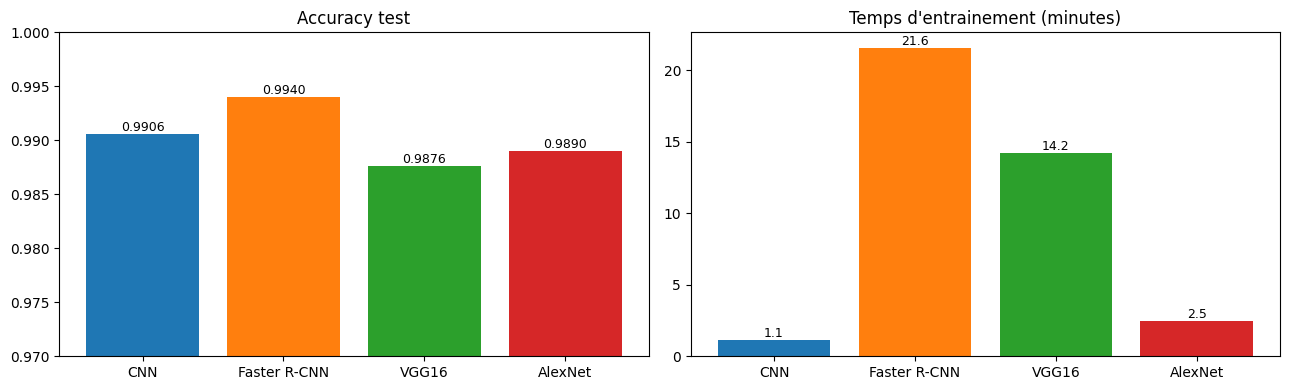

In [ ]:
# Conclusion de la question 4 : tableau complet des 4 architectures + interprete
import pandas as pd
import matplotlib.pyplot as plt

bilan = pd.DataFrame({
    "Accuracy test"  : [accuracy_cnn, accuracy_frcnn, met_vgg16["accuracy"], met_alexnet["accuracy"]],
    "F1 macro"       : [f1_cnn, f1_frcnn, met_vgg16["f1"], met_alexnet["f1"]],
    "Loss test"      : [loss_test_cnn, loss_test_frcnn, met_vgg16["loss"], met_alexnet["loss"]],
    "Entrainement (min)" : [temps_entrainement_cnn / 60, temps_entrainement_frcnn / 60,
                            met_vgg16["temps"] / 60, met_alexnet["temps"] / 60],
}, index=["CNN from scratch", "Faster R-CNN", "VGG16 (transfert)", "AlexNet (transfert)"])
bilan = bilan.style.format({"Accuracy test": "{:.4f}", "F1 macro": "{:.4f}", "Loss test": "{:.4f}", "Entrainement (min)": "{:.1f}"})
display(bilan)

etiquettes = ["CNN", "Faster R-CNN", "VGG16", "AlexNet"]
valeurs_acc = [accuracy_cnn, accuracy_frcnn, met_vgg16["accuracy"], met_alexnet["accuracy"]]
valeurs_tem = [temps_entrainement_cnn / 60, temps_entrainement_frcnn / 60, met_vgg16["temps"] / 60, met_alexnet["temps"] / 60]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(etiquettes, valeurs_acc, color=["tab:blue", "tab:orange", "tab:green", "tab:red"])
ax[0].set_ylim(0.97, 1.0); ax[0].set_title("Accuracy test")
for i, v in enumerate(valeurs_acc): ax[0].text(i, v, f"{v:.4f}", ha="center", va="bottom", fontsize=9)
ax[1].bar(etiquettes, valeurs_tem, color=["tab:blue", "tab:orange", "tab:green", "tab:red"])
ax[1].set_title("Temps d'entrainement (minutes)")
for i, v in enumerate(valeurs_tem): ax[1].text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig("comparaison_finale_partie1.png", dpi=120, bbox_inches="tight")
plt.show()

# Conclusion de la partie 1
#
# **Les quatre architectures arrivent à des scores très proches (98,7 - 99,4 %) : le chiffre MNIST est un
# problème simple, aucune architecture ne le rate.** Ce sont les **coûts** qui les séparent :
#
# | Architecture | Ce qu'il faut retenir |
# |---|---|
# | **CNN from scratch (0,4 M params)** | 99,06 % en **1,1 min** : le meilleur compromis. Petit, entraîné de zéro sur une tâche simple, il fait tout ce qu'on lui demande. |
# | **Faster R-CNN (19 M params)** | 99,40 % mais **21,5 min** : 19× plus lent. Sa puissance (RPN, boîtes, FPN) est inutile pour classer une image contenant un seul objet centré. C'est la bonne architecture pour **localiser** des objets, pas pour les classer. |
# | **VGG16 transfert (120 M entraînables)** | 98,76 % en **14 min** : le plus lourd pour le moins bon score. Ses paramètres ImageNet sont massifs pour une image 28x28 passée en 224x224, et les statistiques ImageNet lui apportent peu. |
# | **AlexNet transfert (55 M entraînables)** | 98,90 % en **2,5 min** : le plus léger des deux pré-entraînés, mais toujours plus lent que le CNN from scratch. |
#
# Le transfert de connaissances depuis **ImageNet (224x224, couleur)** n'a pas d'apport net sur **MNIST (28x28,
# niveaux de gris)** : les features générales de COCO/ImageNet ne compensent ni le coût de calcul, ni
# l'agrandissement artificiel de l'image.
#
# En clair : sur une tâche aussi simple, **un petit CNN entraîné de zéro est plus efficace** qu'une architecture
# lourde en transfert ; le transfert ImageNet n'apporte rien ici.